In [66]:
import pandas as pd
import matplotlib.pyplot as plt

In [67]:
df = pd.read_csv("test_dataset_with_anomaly_predictions.csv")

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

In [68]:
# =========================
# 2. Create Useful Columns
# =========================

df["Total_Downstream_Supply"] = (
    df["LNG_Gas_Supply_Received"] +
    df["Power_Gas_Supply_Received"] +
    df["PCG_Gas_Supply_Received"]
)

df["Total_Downstream_Output"] = (
    df["LNG_Plant_Output"] +
    df["Power_Plant_Output"] +
    df["PCG_Plant_Output"]
)

# All system-level anomalies detected by Isolation Forest
system_anomalies = df[df["Predicted_Anomaly"] == 1]

# Upstream-related anomalies only
upstream_anomalies = df[
    (df["Predicted_Anomaly"] == 1) &
    (df["Upstream_Status"] != "Normal")
]

# Midstream compressor/local anomalies only
compressor_anomalies = df[
    (df["Predicted_Anomaly"] == 1) &
    (df["Midstream_Status"] == "Compressor Fault")
]


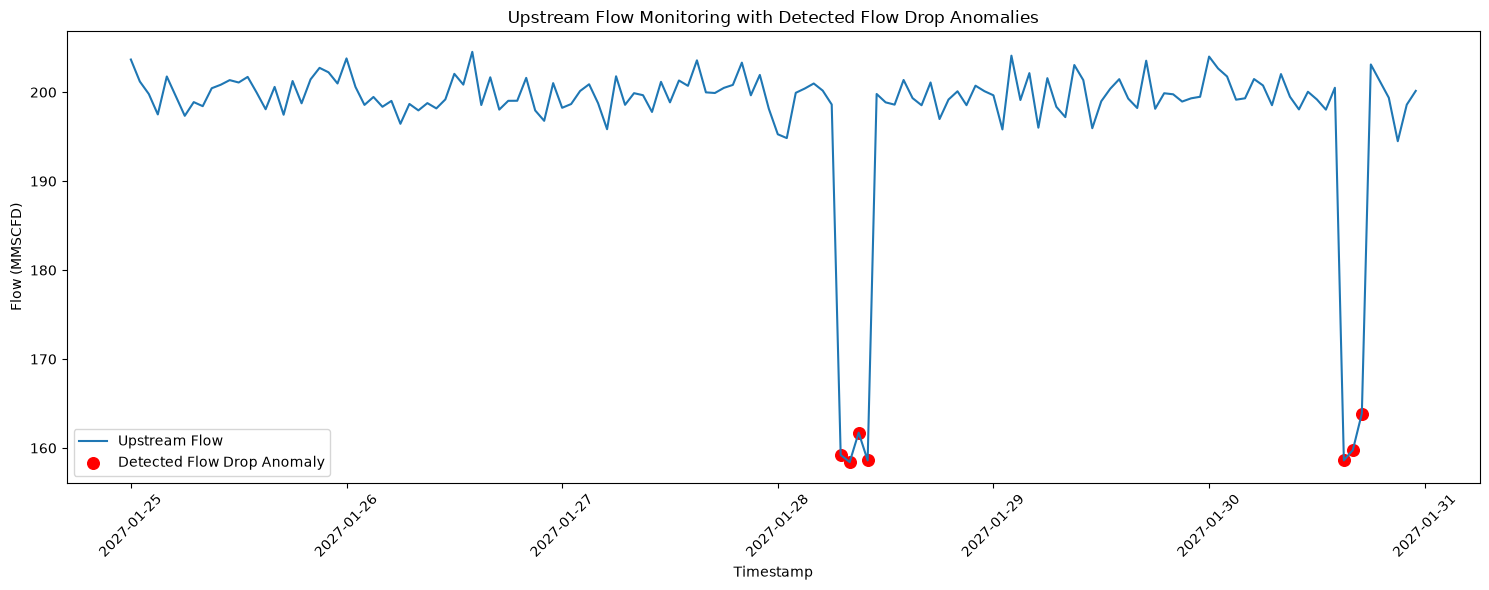

In [69]:
# =========================
# 3. Figure A: Upstream Flow Drop Anomalies Only
# =========================

plt.figure(figsize=(15, 6))

plt.plot(
    df["Timestamp"],
    df["Upstream_Flow"],
    label="Upstream Flow"
)

plt.scatter(
    upstream_anomalies["Timestamp"],
    upstream_anomalies["Upstream_Flow"],
    color="red",
    s=70,
    label="Detected Flow Drop Anomaly"
)

plt.title("Upstream Flow Monitoring with Detected Flow Drop Anomalies")
plt.xlabel("Timestamp")
plt.ylabel("Flow (MMSCFD)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

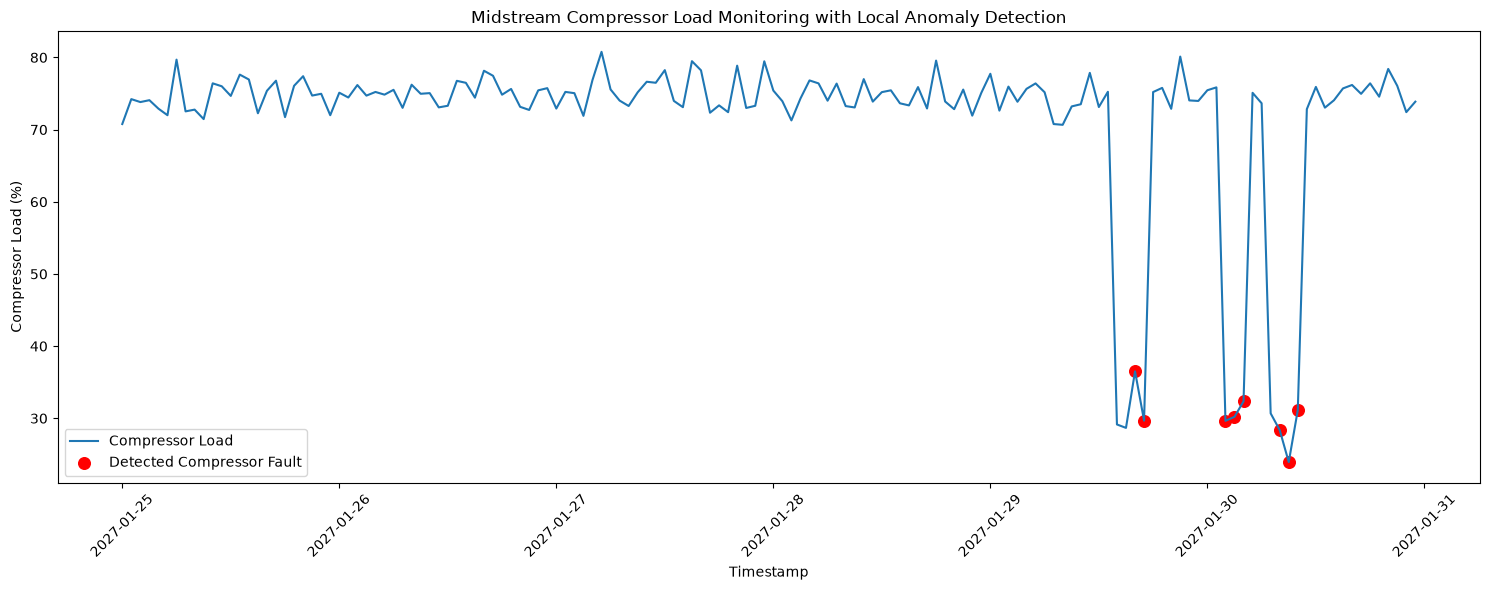

In [70]:
# =========================
# 4. Figure B: Compressor Load Local Anomalies Only
# =========================

plt.figure(figsize=(15, 6))

plt.plot(
    df["Timestamp"],
    df["Midstream_Compressor_Load"],
    label="Compressor Load"
)

plt.scatter(
    compressor_anomalies["Timestamp"],
    compressor_anomalies["Midstream_Compressor_Load"],
    color="red",
    s=70,
    label="Detected Compressor Fault"
)

plt.title("Midstream Compressor Load Monitoring with Local Anomaly Detection")
plt.xlabel("Timestamp")
plt.ylabel("Compressor Load (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


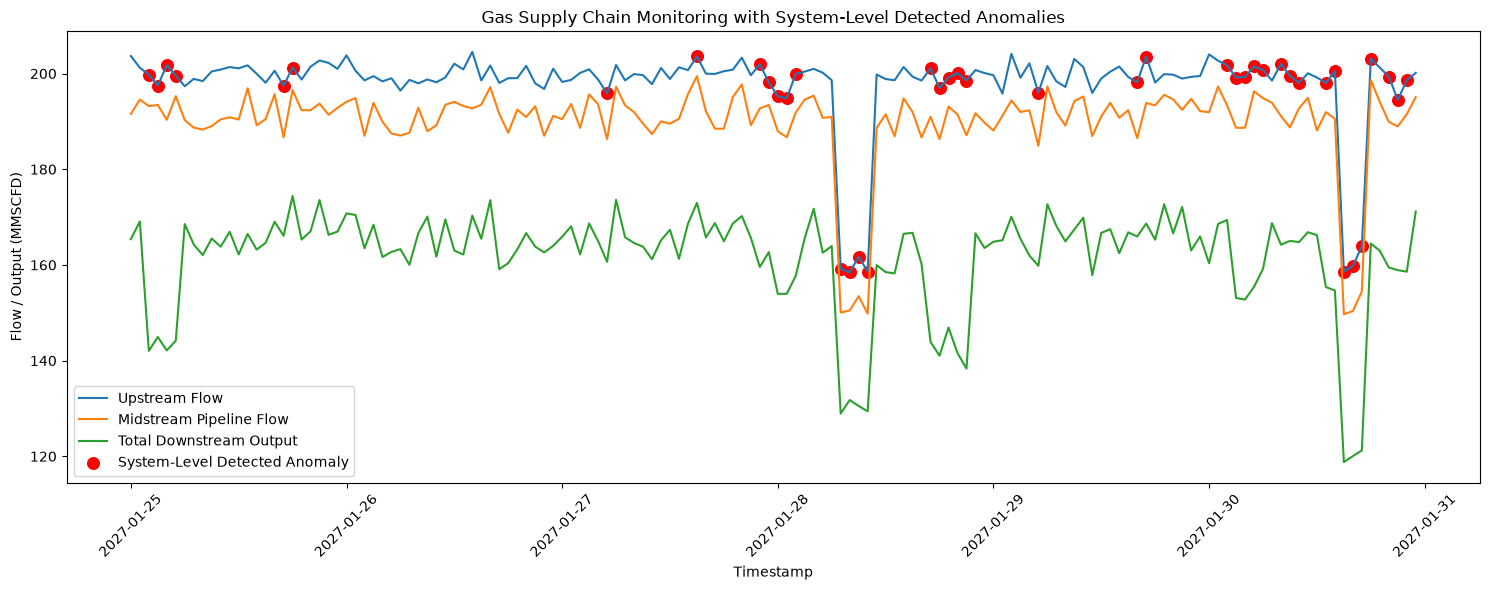

In [71]:
# =========================
# 5. Figure C: Overall System-Level Monitoring
# =========================

plt.figure(figsize=(15, 6))

plt.plot(
    df["Timestamp"],
    df["Upstream_Flow"],
    label="Upstream Flow"
)

plt.plot(
    df["Timestamp"],
    df["Midstream_Pipeline_Flow"],
    label="Midstream Pipeline Flow"
)

plt.plot(
    df["Timestamp"],
    df["Total_Downstream_Output"],
    label="Total Downstream Output"
)

plt.scatter(
    system_anomalies["Timestamp"],
    system_anomalies["Upstream_Flow"],
    color="red",
    s=70,
    label="System-Level Detected Anomaly"
)

plt.title("Gas Supply Chain Monitoring with System-Level Detected Anomalies")
plt.xlabel("Timestamp")
plt.ylabel("Flow / Output (MMSCFD)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

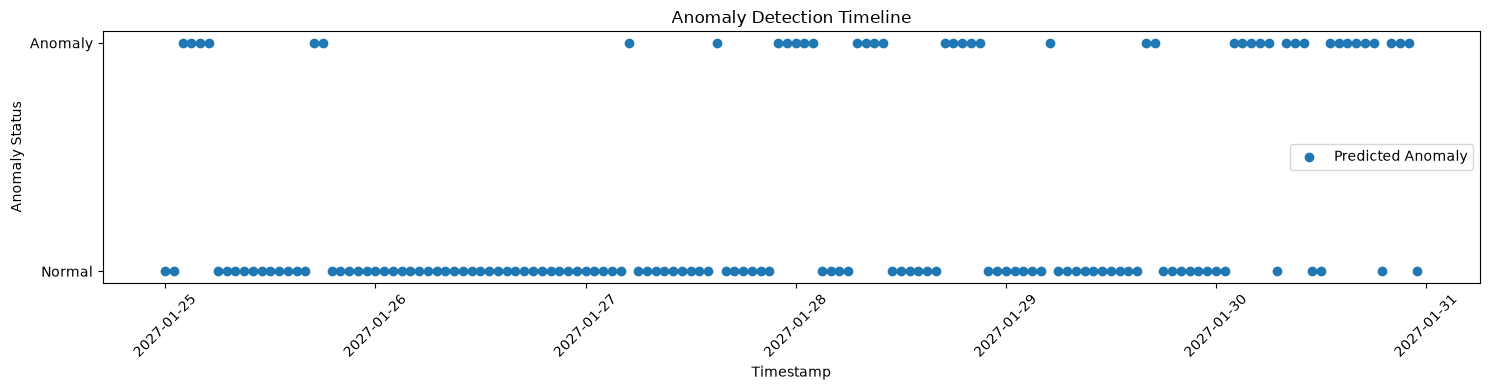

In [72]:
# =========================
# 6. Figure D: Anomaly Detection Timeline
# =========================

plt.figure(figsize=(15, 4))

plt.scatter(
    df["Timestamp"],
    df["Predicted_Anomaly"],
    label="Predicted Anomaly"
)

plt.title("Anomaly Detection Timeline")
plt.xlabel("Timestamp")
plt.ylabel("Anomaly Status")
plt.yticks([0, 1], ["Normal", "Anomaly"])
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


In [73]:
# =========================
# 7. Print Summary
# =========================

print("\n===== Visualization Summary =====")
print(f"Total testing records: {len(df)}")
print(f"System-level detected anomalies: {len(system_anomalies)}")
print(f"Detected upstream flow drop anomalies: {len(upstream_anomalies)}")
print(f"Detected compressor fault anomalies: {len(compressor_anomalies)}")

print("\n===== Detected Anomaly Type Summary =====")
print(
    system_anomalies["GroundTruth_Status_Summary"]
    .value_counts()
)

print("\n===== System-Level Detected Anomaly Records =====")
print(
    system_anomalies[
        [
            "Timestamp",
            "Upstream_Status",
            "Midstream_Status",
            "LNG_Status",
            "Power_Status",
            "PCG_Status",
            "GroundTruth_Status_Summary",
            "Detection_Result"
        ]
    ]
)


===== Visualization Summary =====
Total testing records: 144
System-level detected anomalies: 42
Detected upstream flow drop anomalies: 7
Detected compressor fault anomalies: 8

===== Detected Anomaly Type Summary =====
GroundTruth_Status_Summary
Underperformance                                                  22
Compressor Fault                                                   6
Normal                                                             5
Flow Drop, Flow Restriction, Supply Shortage                       4
Flow Drop, Flow Restriction, Supply Shortage, Underperformance     3
Compressor Fault, Underperformance                                 2
Name: count, dtype: int64

===== System-Level Detected Anomaly Records =====
              Timestamp Upstream_Status  Midstream_Status        LNG_Status  \
2   2027-01-25 02:00:00          Normal            Normal  Underperformance   
3   2027-01-25 03:00:00          Normal            Normal  Underperformance   
4   2027-01-25 04:00:00 